In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Read data
df = pd.read_excel("classification_task1_train.xlsx")

df["Date"] = pd.to_datetime(df["Date"])

In [3]:
df.shape

(1063, 12)

In [4]:
print("--- Resumo da Estrutura dos Dados ---")
print(f"Número de registos: {len(df)}")
print(f"Valores em falta por coluna:\n{df.isnull().sum()}\n")

--- Resumo da Estrutura dos Dados ---
Número de registos: 1063
Valores em falta por coluna:
Date                 0
Day                  0
Month                0
Year                 0
Season               0
CHL                500
CHL_uncertainty    500
SST                  0
UI                   0
YDOY                 0
spatial_cluster      0
HAB                  0
dtype: int64



In [5]:
df.head()

,Date,Day,Month,Year,Season,CHL,CHL_uncertainty,SST,UI,YDOY,spatial_cluster,HAB
0,2013-02-19,19,2,2013,Winter,NaN,NaN,12.63,0.003952,0.651899,0,0
1,2013-02-27,27,2,2013,Winter,NaN,NaN,12.54,0.949088,0.541628,0,0
2,2013-03-04,4,3,2013,Spring,NaN,NaN,13.56,0.147877,0.467359,0,0
3,2013-03-13,13,3,2013,Spring,1.419613,19.6,12.60,1.041656,0.325342,0,0
4,2013-03-19,19,3,2013,Spring,NaN,NaN,12.26,0.003219,0.226116,0,0


In [6]:
df.describe()

,Date,Day,Month,Year,CHL,CHL_uncertainty,SST,UI,YDOY,spatial_cluster,HAB
count,1063,1063.000000,1063.000000,1063.000000,563.000000,563.000000,1063.000000,1063.000000,1063.000000,1063.000000,1063.000000
mean,2017-06-29 18:33:31.665098,15.432738,6.523989,2016.995296,5.657638,39.025310,14.646971,0.054590,-0.035420,2.208843,0.129821
min,2013-02-19 00:00:00,1.000000,1.000000,2013.000000,0.353574,6.740000,11.210000,-1.984056,-0.999963,0.000000,0.000000
25%,2016-01-29 00:00:00,8.000000,4.000000,2016.000000,1.777212,19.675000,13.410000,-0.040358,-0.696376,0.000000,0.000000
50%,2017-09-04 00:00:00,15.000000,7.000000,2017.000000,2.925195,32.480000,14.450000,0.038991,-0.098820,2.000000,0.000000
75%,2019-04-16 00:00:00,22.000000,9.000000,2019.000000,5.961410,57.969999,15.640000,0.188376,0.651899,4.000000,0.000000
max,2020-12-29 00:00:00,31.000000,12.000000,2020.000000,62.731522,92.739998,20.740000,2.000225,0.999852,5.000000,1.000000
std,NaN,8.614628,3.355735,2.205322,7.990471,21.722530,1.680171,0.377639,0.692179,2.146174,0.336265


In [7]:
CONTINUOUS = ["CHL", "CHL_uncertainty", "SST", "UI", "YDOY"]
DISCRETE = ["spatial_cluster", "HAB"]
HIST_VARS = CONTINUOUS + DISCRETE

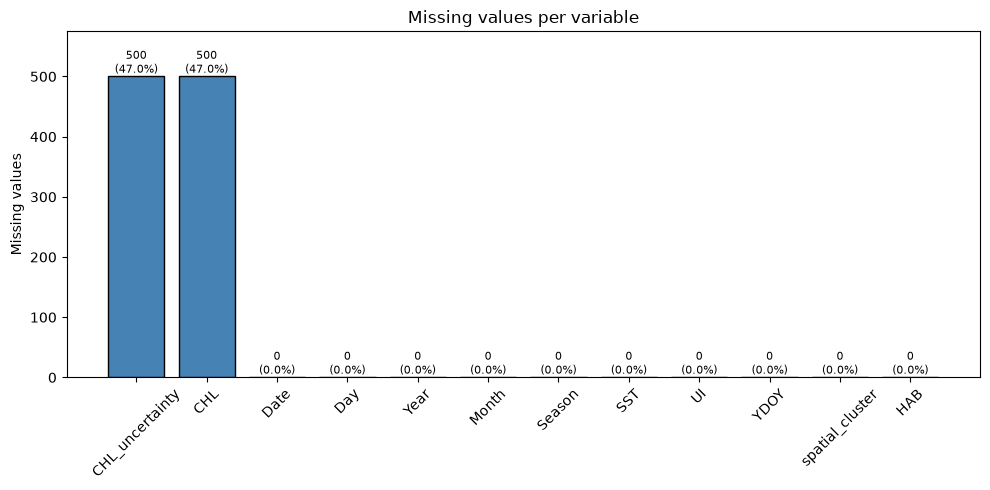

In [8]:
# Bar chart of missing values per variable

missing = df.isna().sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(missing.index, missing.values, color="steelblue", edgecolor="k")
for b, v in zip(bars, missing.values):
    pct = 100 * v / len(df) # percentage missing
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v}\n({pct:.1f}%)",
            ha="center", va="bottom", fontsize=8)
ax.set_ylabel("Missing values")
ax.set_title("Missing values per variable")
ax.tick_params(axis="x", rotation=45)
ax.set_ylim(0, max(missing.max() * 1.15, 1))
fig.tight_layout()
plt.show()

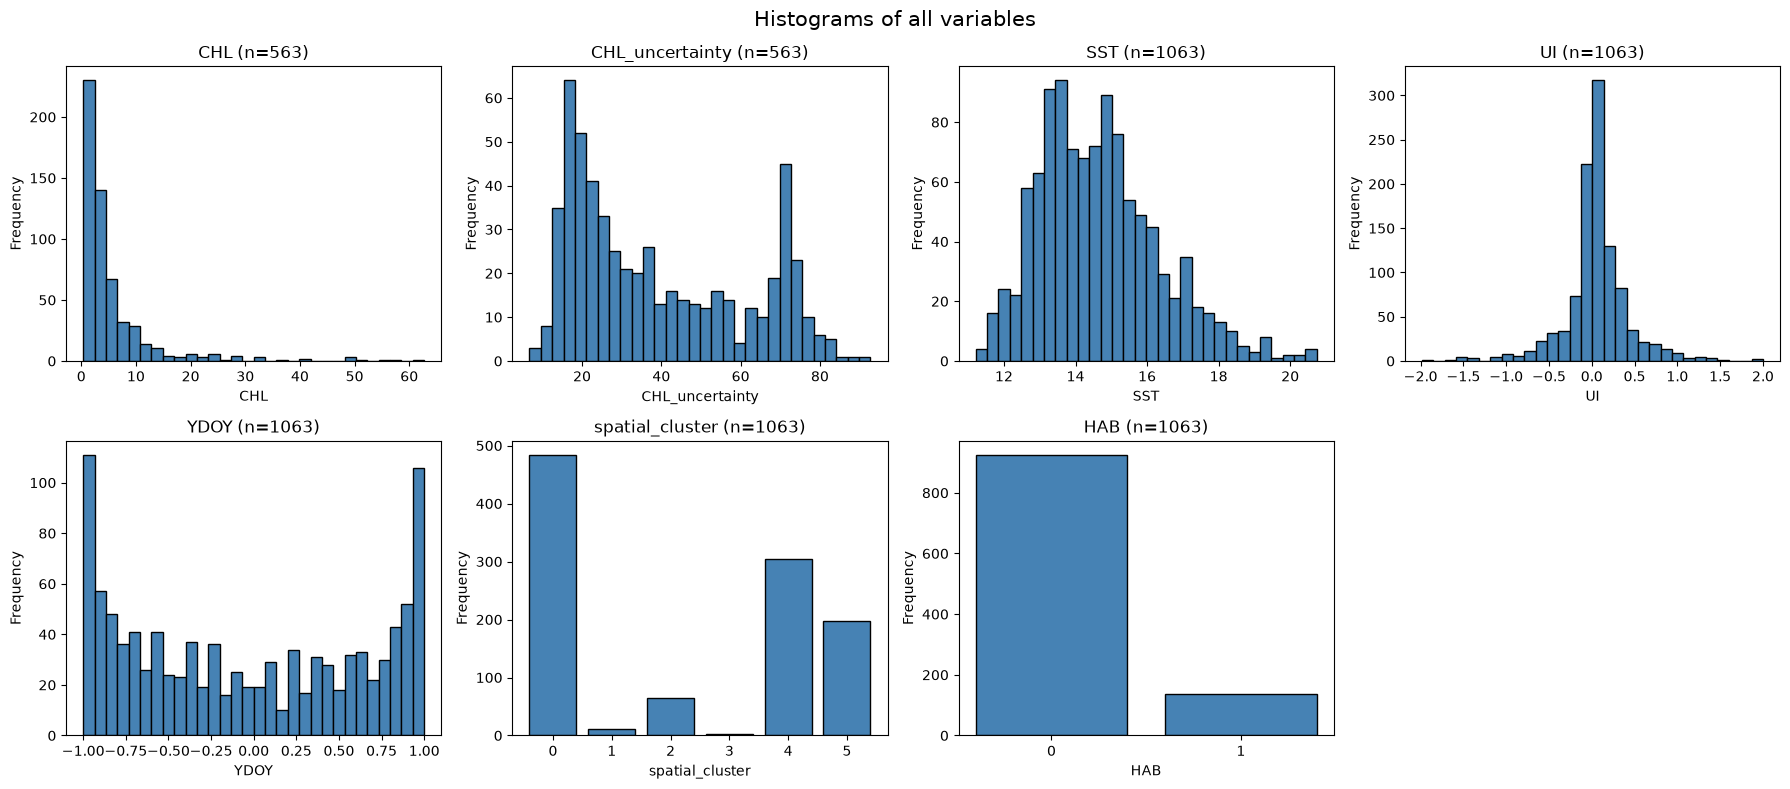

In [9]:
# Histograms of all variables
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()
for ax, col in zip(axes, HIST_VARS):
    data = df[col].dropna()
    if col in DISCRETE: # para os bins serem 0, 1, 2, etc.
        counts = data.value_counts().sort_index()
        ax.bar(counts.index.astype(str), counts.values, color="steelblue", edgecolor="k")
    else:
        ax.hist(data, bins=30, color="steelblue", edgecolor="k")
    ax.set_title(f"{col} (n={len(data)})")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
for ax in axes[len(HIST_VARS):]:
    ax.axis("off")
fig.suptitle("Histograms of all variables", fontsize=15)
fig.tight_layout()
plt.show()


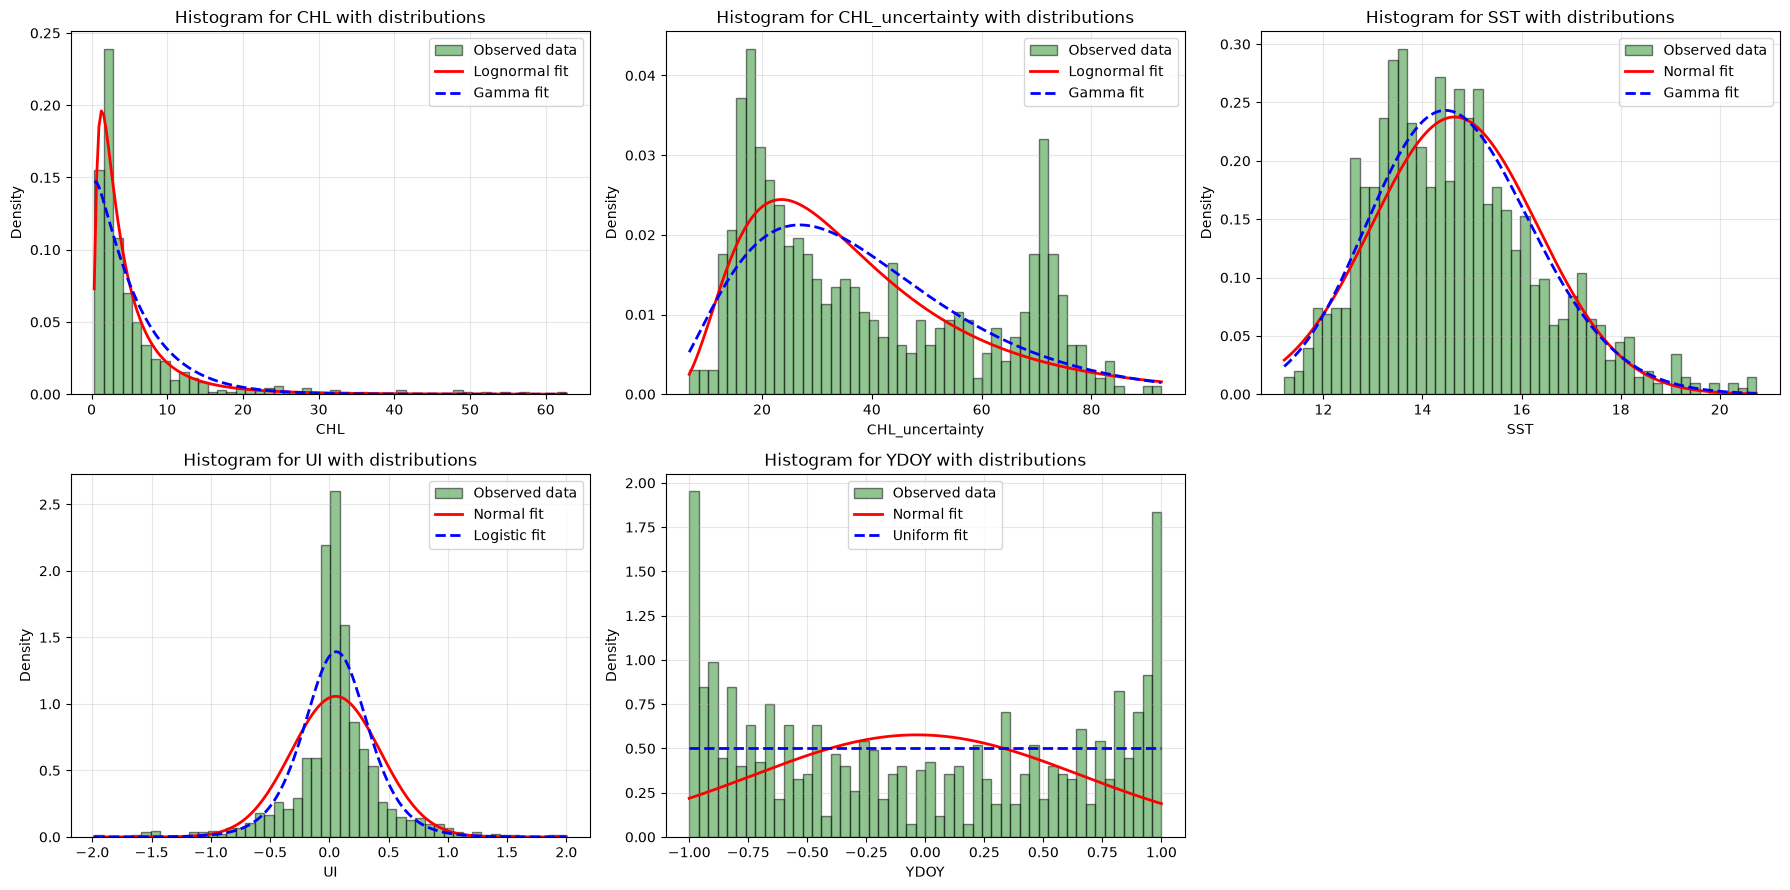

In [10]:
# Best fit

# Which distributions to fit
dists = {
    "CHL":             [("Lognormal", stats.lognorm, True), ("Gamma", stats.gamma, True)],
    "CHL_uncertainty": [("Lognormal", stats.lognorm, True), ("Gamma", stats.gamma, True)],
    "SST":             [("Normal", stats.norm, False), ("Gamma", stats.gamma, True)],
    "UI":              [("Normal", stats.norm, False), ("Logistic", stats.logistic, False)],
    "YDOY":            [("Normal", stats.norm, False), ("Uniform", stats.uniform, False)],
}
styles = ["r-", "b--"]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.ravel()

for ax, (col, fits) in zip(axes, dists.items()):
    data = df[col].dropna()
    x = np.linspace(data.min(), data.max(), 200)

    ax.hist(data, bins=50, density=True, color="forestgreen",
            edgecolor="black", alpha=0.5, label="Observed data")

    for (name, dist, fix_loc), style in zip(fits, styles):
        params = dist.fit(data, floc=0) if fix_loc else dist.fit(data)
        ax.plot(x, dist.pdf(x, *params), style, linewidth=2, label=f"{name} fit")

    ax.set_title(f"Histogram for {col} with distributions")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(True, alpha=0.3)

axes[-1].axis("off")   # 5 variables, 6 panels
fig.tight_layout()
plt.show()

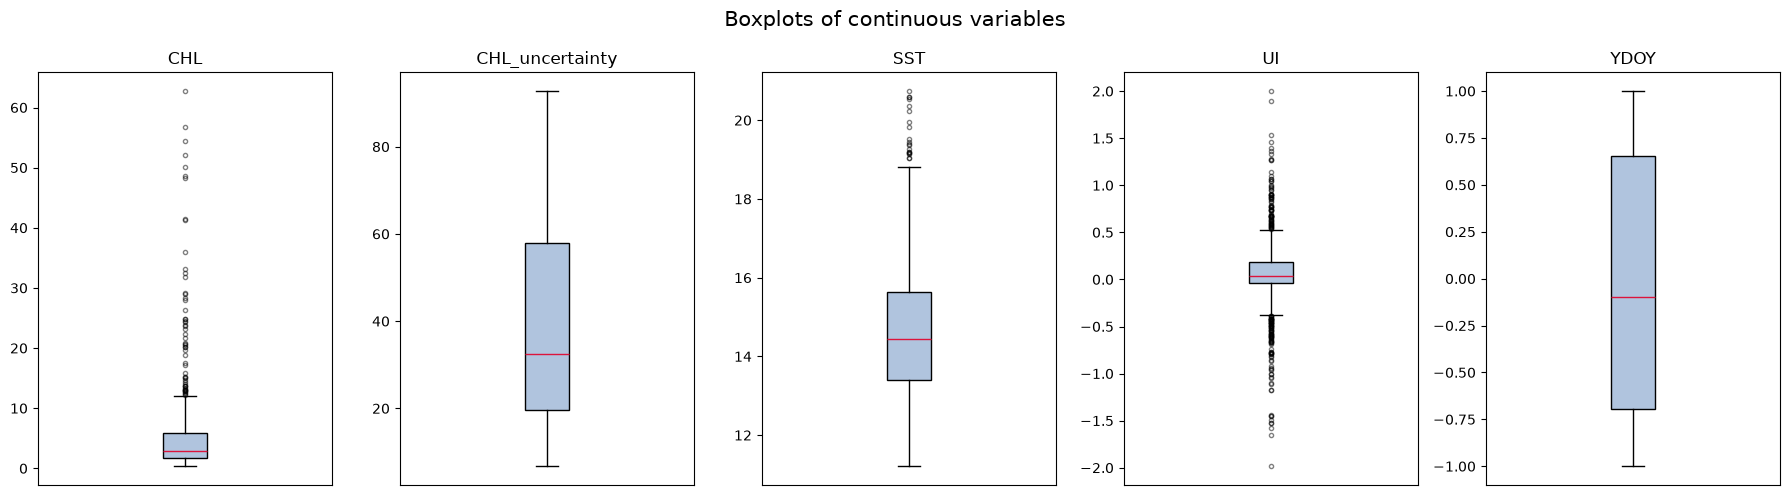

In [11]:
# Boxplots
fig, axes = plt.subplots(1, len(CONTINUOUS), figsize=(18, 5))
for ax, col in zip(axes, CONTINUOUS):
    ax.boxplot(df[col].dropna(), patch_artist=True,
               boxprops=dict(facecolor="lightsteelblue"),
               medianprops=dict(color="crimson"),
               flierprops=dict(marker="o", markersize=3, alpha=0.5))
    ax.set_title(col)
    ax.set_xticks([])
fig.suptitle("Boxplots of continuous variables", fontsize=15)
fig.tight_layout()
plt.show()


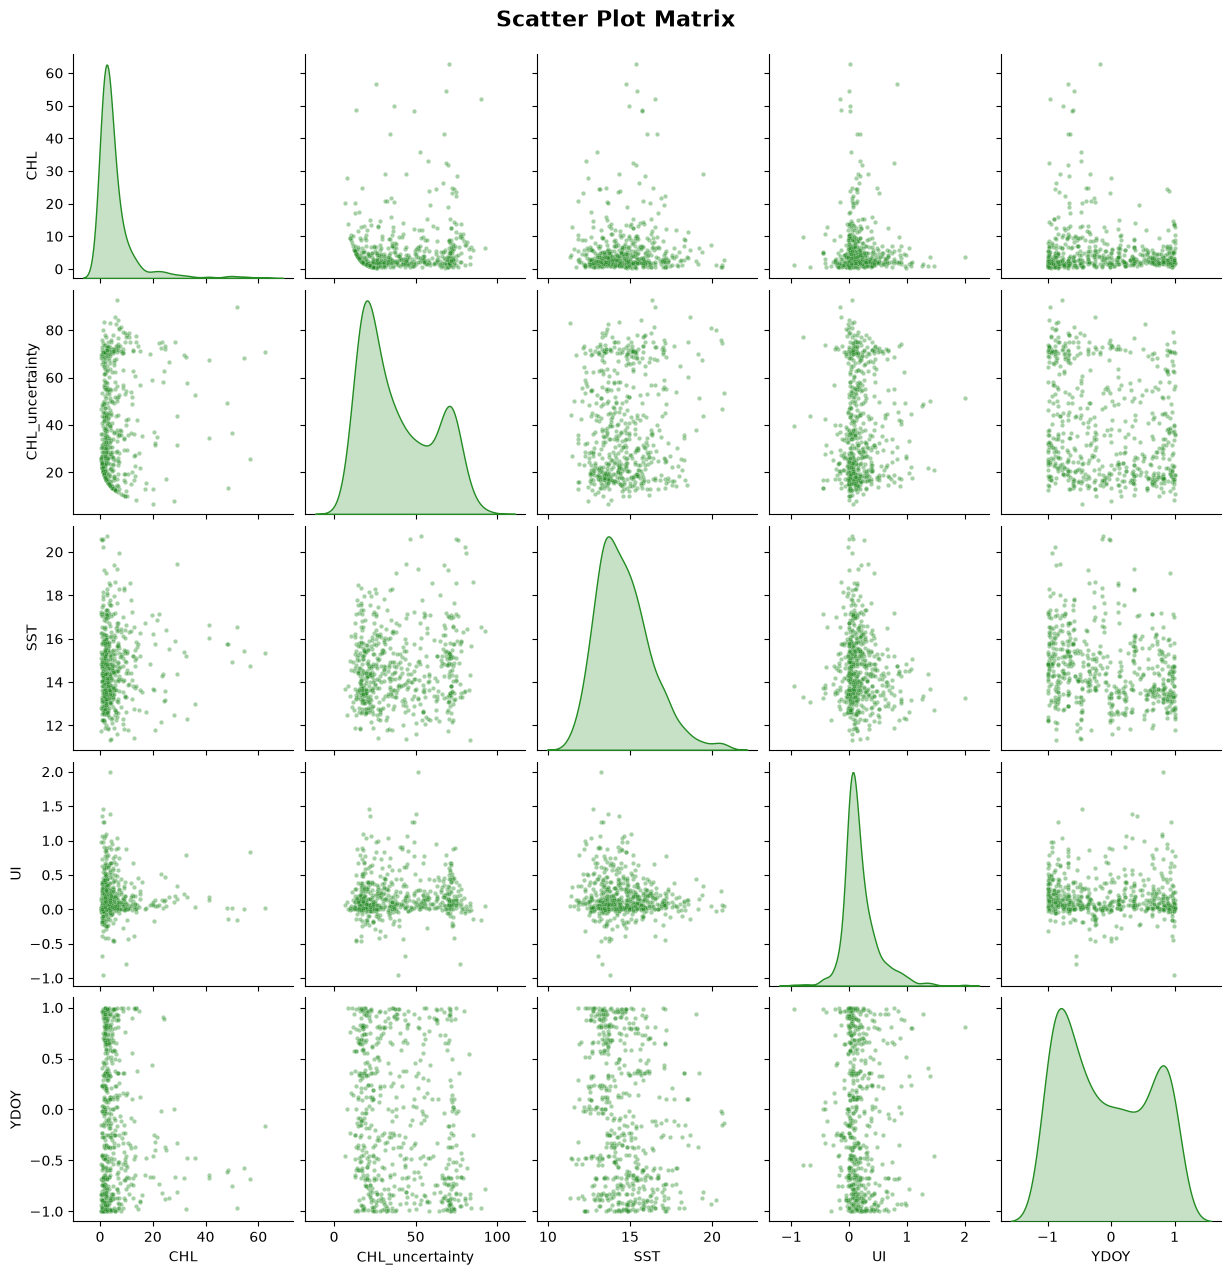

In [12]:
# Scatter plot matrix for the continuous variables
pairplot_fig = sns.pairplot(
    df[CONTINUOUS].dropna(),
    diag_kind="kde",
    plot_kws={"alpha": 0.4, "s": 10, "color": "forestgreen"},
    diag_kws={"color": "forestgreen"}
)
pairplot_fig.fig.suptitle("Scatter Plot Matrix", y=1.02, fontsize=16, fontweight="bold")
plt.show()

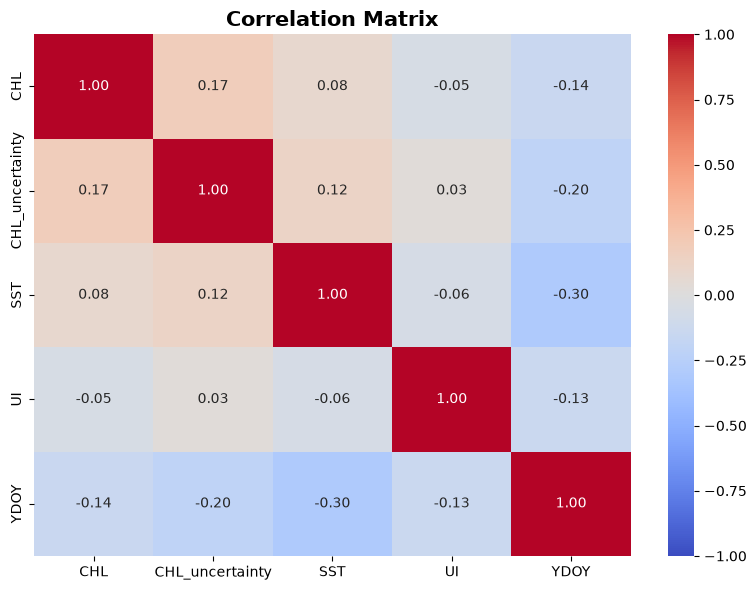

In [13]:
# Correlation matrix for the continuous variables
corr = df[CONTINUOUS].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1)
ax.set_title("Correlation Matrix", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()